## Author: Gabriel Vance
## Class: DSC630 - Predictive Analytics
## Professor: Professor Andrew Hua
## Date: November 8, 2025
# Fake News Detection Using NLP Techniques



Lies have always been a part of human society and communication. Simply put, lies are saying something that is not true. Fake news is another term for lies. It presents itself as a legitimate update in the world without maintain a factual basis. 

When journalism and technology merged, the dispersion of fake news changed from supermarket tabloids and talk radio to webpages, social media, and now AI generated content. It is increasingly more believable, viral, and widespread. Foreign states, activists, and grifters are spreading fake news to achieve their political, influential and financial ends. But while technology is partially responsible for the rise and proliferation of fake news, it can also substantially aid in combating these lies.

For my project, I chose to use a natural language processor to identify fake news. The assumption was that fake news or lies contained a certain language or pattern structure that stood out from truthful news. This is likely due to fake news largely being “spam” or manufactured news, so in essence, machines were generating fake news and left a “watermark” that was easily predictable, like spam or malware. 
For imports, we will use traditional python data analysis tools as well as the NLP libraries Textblob and VADER. For prediction, we will use sklearn.


### Imports

In [170]:
# Standard library
import re
from collections import Counter

# Data manipulation and analysis
import numpy as np
import pandas as pd

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Statistics
from scipy.stats import skew, kurtosis

# Text processing / NLP
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import DistilBertTokenizerFast, TFDistilBertForSequenceClassification

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Deep learning
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from transformers import DistilBertTokenizerFast, TFDistilBertForSequenceClassification
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
import numpy as np


# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Ensure that all code cells are fully visible without scrolling
from IPython.core.display import display, HTML

display(HTML('''
<style>
div.CodeMirror pre {
    white-space: pre !important;
}
</style>
'''))


### Task 1: Understand data shape

The dataset for this notebook was provided by https://www.kaggle.com/datasets/algord/fake-news. I intentionally chose one of the most popular datasets on Kaggle that has already been downloaded over 10,000 times. The dataset contains 626 real news articles and 434 fake news articles. 

Read data in

In [171]:
politics_real_df = pd.read_csv('github_set1/politifact_real.csv')
politics_fake_df = pd.read_csv('github_set1/politifact_fake.csv')


### Examine the shape of data

In [172]:
politics_real_df.head()
# the shape is the same for fake and real

,id,news_url,title,tweet_ids
0,politifact14984,http://www.nfib-sbet.org/,National Federation of Independent Business,967132259869487105\t967164368768196609\t967215...
1,politifact12944,http://www.cq.com/doc/newsmakertranscripts-494...,comments in Fayetteville NC,942953459\t8980098198\t16253717352\t1668513250...
2,politifact333,https://web.archive.org/web/20080204072132/htt...,"Romney makes pitch, hoping to close deal : Ele...",NaN
3,politifact4358,https://web.archive.org/web/20110811143753/htt...,Democratic Leaders Say House Democrats Are Uni...,NaN
4,politifact779,https://web.archive.org/web/20070820164107/htt...,"Budget of the United States Government, FY 2008",89804710374154240\t91270460595109888\t96039619...


### Task 1 Conclusion: Understand data shape 

The dataset contains the following columns:

 id - unique identifier for each article
 news_url - news soiurce URL
 title - title of the article
 text - text of the article
 tweet_ids  - tweet IDs associated with the article. to find the tweet, append the id to https://twitter.com/i/web/status/{{tweet_id}} i.e. https://twitter.com/i/web/status/284329075902926848

 Each row is a single instance of an article. The title is the headline of the article. The news url is the source of the article. Tweet IDs are the number of tweets that shared the article. Other fake news datasets contain the actual text of the article, but this isn't required for classifying fake news. Using only the title allows us to expedite model comparison and training time. 

Tweet IDs can be used for manually looking up the actual tweet via the twitter API/URL. 



### Task 2: Exploratory Data Analysis (EDA)

The tweet IDs are separated by white space or '\t'. We'll separate them to get the number of tweets per article.

In [173]:
# Create number of tweets column to understand engagement, set to 0 if no tweets
politics_real_df['number_of_tweets'] = politics_real_df['tweet_ids'].apply(lambda x: 0 if pd.isna(x) else len(str(x).split('\t')))
politics_fake_df['number_of_tweets'] = politics_fake_df['tweet_ids'].apply(lambda x: 0 if pd.isna(x) else len(str(x).split('\t')))
politics_real_df[['tweet_ids', 'number_of_tweets']].head()


,tweet_ids,number_of_tweets
0,967132259869487105\t967164368768196609\t967215...,1174
1,942953459\t8980098198\t16253717352\t1668513250...,51
2,NaN,0
3,NaN,0
4,89804710374154240\t91270460595109888\t96039619...,8


With the new number_of_tweets column, we can analyze the engagement of real vs fake news articles.

In [174]:
# Calculate mean number of tweet_ids for fake and real dataframes
mean_fake_tweet_ids = politics_fake_df['number_of_tweets'].mean()
mean_real_tweet_ids = politics_real_df['number_of_tweets'].mean()

print(f"Mean # of tweet_ids (fake): {mean_fake_tweet_ids:.2f}")
print(f"Mean # of tweet_ids (real): {mean_real_tweet_ids:.2f}")

Mean # of tweet_ids (fake): 382.76
Mean # of tweet_ids (real): 670.13


In [175]:
num_fake_zeros = (politics_fake_df['number_of_tweets'] == 0).sum()
num_real_zeros = (politics_real_df['number_of_tweets'] == 0).sum()

percent_fake_zeros = num_fake_zeros / len(politics_fake_df) * 100
percent_real_zeros = num_real_zeros / len(politics_real_df) * 100

print(f"Number of fake articles with 0 tweets: {num_fake_zeros} ({percent_fake_zeros:.2f}%)")
print(f"Number of real articles with 0 tweets: {num_real_zeros} ({percent_real_zeros:.2f}%)")

Number of fake articles with 0 tweets: 40 (9.26%)
Number of real articles with 0 tweets: 215 (34.46%)


Without standardization, the mean tweets for real news articles is higher than that of fake news articles. When comparing articles with 0 tweets, we see that more than 30% of all real articles have 0 tweets whereas only 9% of fake articles have 0 tweets. We'll standardize the number of tweets and conduct another comparison of mean tweets.

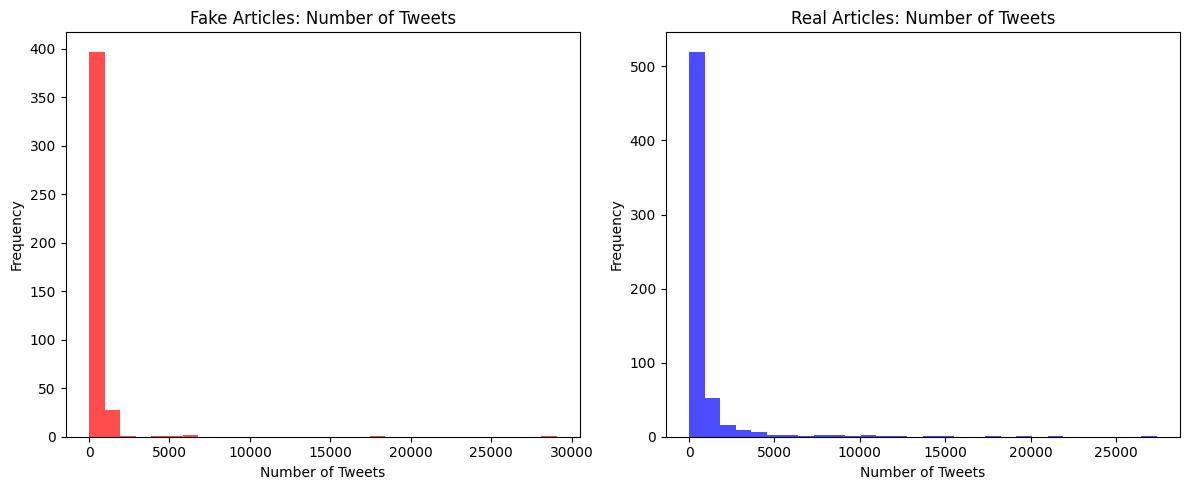

In [176]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(politics_fake_df['number_of_tweets'], bins=30, color='red', alpha=0.7)
plt.title('Fake Articles: Number of Tweets')
plt.xlabel('Number of Tweets')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(politics_real_df['number_of_tweets'], bins=30, color='blue', alpha=0.7)
plt.title('Real Articles: Number of Tweets')
plt.xlabel('Number of Tweets')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [177]:
# Skewness and kurtosis for number_of_tweets
fake_skew = skew(politics_fake_df['number_of_tweets'])
real_skew = skew(politics_real_df['number_of_tweets'])
fake_kurt = kurtosis(politics_fake_df['number_of_tweets'])
real_kurt = kurtosis(politics_real_df['number_of_tweets'])

print(f"Fake Articles - Skewness: {fake_skew:.2f}, Kurtosis: {fake_kurt:.2f}")
print(f"Real Articles - Skewness: {real_skew:.2f}, Kurtosis: {real_kurt:.2f}")

Fake Articles - Skewness: 13.16, Kurtosis: 196.74
Real Articles - Skewness: 6.55, Kurtosis: 52.10


Fake news' kurtosis for number of tweets is significantly higher. The number of tweets for real news, while skewed, is more natural and less extremely skewed.

In [178]:
print("Fake Articles - Number of Tweets Distribution:")
print(politics_fake_df['number_of_tweets'].describe())
print("\nReal Articles - Number of Tweets Distribution:")
print(politics_real_df['number_of_tweets'].describe())

Fake Articles - Number of Tweets Distribution:
count      432.000000
mean       382.759259
std       1728.420580
min          0.000000
25%         12.000000
50%         79.000000
75%        291.500000
max      29060.000000
Name: number_of_tweets, dtype: float64

Real Articles - Number of Tweets Distribution:
count      624.000000
mean       670.134615
std       2357.062320
min          0.000000
25%          0.000000
50%          8.000000
75%        167.000000
max      27377.000000
Name: number_of_tweets, dtype: float64


Just to get a sense of the types of articles, we'll look at the 5 articles with 0 retweet and the top 5 tweeted articles.

In [179]:
# Titles with number_of_tweets == 0 (first 5)
print("Titles with 0 tweets (first 5):")
for title in politics_real_df[politics_real_df['number_of_tweets'] == 0]['title'].head(5):
    print(title)

# Titles with highest number_of_tweets (top 5)
print("\nTitles with highest tweet counts (top 5):")
for title in politics_real_df.sort_values('number_of_tweets', ascending=False)['title'].head(5):
    print(title)

Titles with 0 tweets (first 5):
Romney makes pitch, hoping to close deal : Elections : The Rocky Mountain News
Democratic Leaders Say House Democrats Are United Against GOP Default Act
子供たちのコト。私のコト。
Covering Young Adults Under the Affordable Care Act: The Importance of Outreach and Medicaid Expansion
Summary of the Affordable Care Act

Titles with highest tweet counts (top 5):
One in Four – Congressman Joe Pitts – Medium
Rep. Michael McCaul (R-TX) Appears on Face the Nation
Outlook, Office, Skype, Bing, Breaking News, and Latest Videos
interview on Fox News
"One Hundred Percent" by Club for Growth Action


Because the number of tweets contains 0, we'll use np.log1p to standardize the data. I chose log1p because it handles 0 values by applying log(1 + x). This allows us to transform the data without losing any instances.

In [180]:
politics_real_df["number_of_tweets_log"] = np.log1p(politics_real_df["number_of_tweets"])  
politics_fake_df["number_of_tweets_log"] = np.log1p(politics_fake_df["number_of_tweets"])  


# Skewness and kurtosis for number_of_tweets
fake_skew_log = skew(politics_fake_df['number_of_tweets_log'])
real_skew_log = skew(politics_real_df['number_of_tweets_log'])
fake_kurt_log = kurtosis(politics_fake_df['number_of_tweets_log'])
real_kurt_log = kurtosis(politics_real_df['number_of_tweets_log'])

print(f"Fake Articles - Skewness: {fake_skew_log:.2f}, Kurtosis: {fake_kurt_log:.2f}")
print(f"Real Articles - Skewness: {real_skew_log:.2f}, Kurtosis: {real_kurt_log:.2f}")

print(f"Fake Articles - Skewness: {fake_skew_log:.2f}, Kurtosis: {fake_kurt_log:.2f}")
print(f"Real Articles - Skewness: {real_skew_log:.2f}, Kurtosis: {real_kurt_log:.2f}")


Fake Articles - Skewness: -0.30, Kurtosis: -0.62
Real Articles - Skewness: 0.61, Kurtosis: -0.95
Fake Articles - Skewness: -0.30, Kurtosis: -0.62
Real Articles - Skewness: 0.61, Kurtosis: -0.95


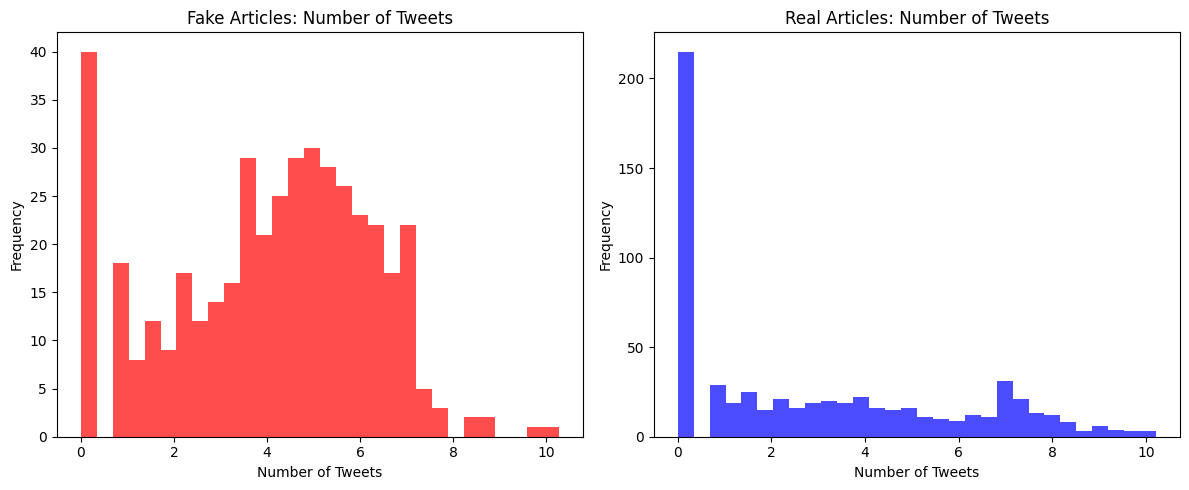

In [181]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(politics_fake_df['number_of_tweets_log'], bins=30, color='red', alpha=0.7)
plt.title('Fake Articles: Number of Tweets')
plt.xlabel('Number of Tweets')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(politics_real_df['number_of_tweets_log'], bins=30, color='blue', alpha=0.7)
plt.title('Real Articles: Number of Tweets')
plt.xlabel('Number of Tweets')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Log appears to given us the best distribution for number of tweets, as both the real and fake articles are closer to 0. The fake news articles are still still skewed but show a much more normal distribution compared to real news. News with 0 tweets will remain in our dataset but their importance has been noted as they are the primary reason for the skewness.

In [182]:

# Calculate mean number of tweet_ids for fake and real dataframes
mean_fake_tweet_ids = politics_fake_df['number_of_tweets_log'].mean()
mean_real_tweet_ids = politics_real_df['number_of_tweets_log'].mean()

print(f"Mean # of tweet_ids (fake): {mean_fake_tweet_ids:.2f}")
print(f"Mean # of tweet_ids (real): {mean_real_tweet_ids:.2f}")

Mean # of tweet_ids (fake): 4.04
Mean # of tweet_ids (real): 2.90


After normalizing, we notice that fake news on average is tweeted higher. Before normalization, real news was tweeted almost twice as much as fake news. How is this possible if 1/3 of all real news has 0 tweets? The likely answer is that a small subset of real news is tweeted tens of thousands of times, so much so that they carry the average tweet count higher than fake news. When standardized, we see that fake news on average is tweeted about 4.04 times vs real news averaging 2.9 tweets. Fake news is tweeted 38% more times than real news.

In [183]:

# Skewness and kurtosis for number_of_tweets
fake_skew_log = skew(politics_fake_df['number_of_tweets_log'])
real_skew_log = skew(politics_real_df['number_of_tweets_log'])
fake_kurt_log = kurtosis(politics_fake_df['number_of_tweets_log'])
real_kurt_log = kurtosis(politics_real_df['number_of_tweets_log'])

print("Before Log Transformation:")

print(f"Fake Articles - Skewness: {fake_skew:.2f}, Kurtosis: {fake_kurt:.2f}")
print(f"Real Articles - Skewness: {real_skew:.2f}, Kurtosis: {real_kurt:.2f}")

print("\nAfter Log Transformation:")

print(f"Fake Articles - Skewness: {fake_skew_log:.2f}, Kurtosis: {fake_kurt_log:.2f}")
print(f"Real Articles - Skewness: {real_skew_log:.2f}, Kurtosis: {real_kurt_log:.2f}")

Before Log Transformation:
Fake Articles - Skewness: 13.16, Kurtosis: 196.74
Real Articles - Skewness: 6.55, Kurtosis: 52.10

After Log Transformation:
Fake Articles - Skewness: -0.30, Kurtosis: -0.62
Real Articles - Skewness: 0.61, Kurtosis: -0.95


# EDA Task 2 - Domains

Domains are the source of news articles. 

Fake → 258 unique domains, 23 unique suffixes
Real → 126 unique domains, 10 unique suffixes

 DOMAIN COMPARISON
Common domains: 20
Unique to fake: 238
Unique to real: 106

Examples of overlapping domains: ['medium', '', 'twitter', 'apnews', 'foxnews', 'washingtonpost', 'thehill', 'nbcnews', 'facebook', 'businessinsider']
Examples unique to fake: ['jumboreport', 'actionnetwork', 'usnews', 'thegoldwater', 'mysteriousearth', 'abcnews-us', 'thesun', 'our', 'yournewswire', 'mainerepublicemailalert']
Examples unique to real: ['usda', 'nexis', 'pbs', 'wisconsin', 'go', 'supremecourt', 'mass', 'brighthorizons', 'latimes', 'guardian']

 SUFFIX COMPARISON
Common suffixes: 6
Unique to fake: 17
Unique to real: 4

Common suffixes: {'', 'com', 'us', 'org', 'co.uk', 'gov'}
Fake-only suffixes: {'tk', 'website', 'net', 'club', 'tv', 'live', 'info', 'ru', 'gov.jm', 'co', 'news', 'site', 'is', 'me', 'one', 'life', 'pw'}
Real-only suffixes: {'mil', 'ak.us', 'be', 'edu'}


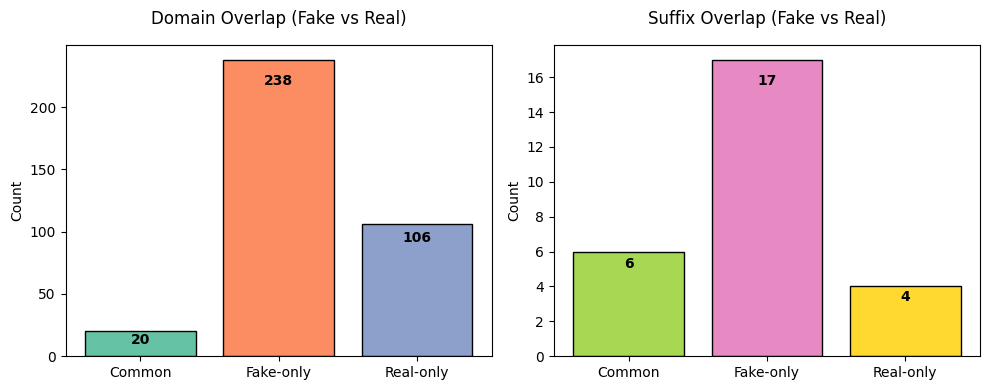

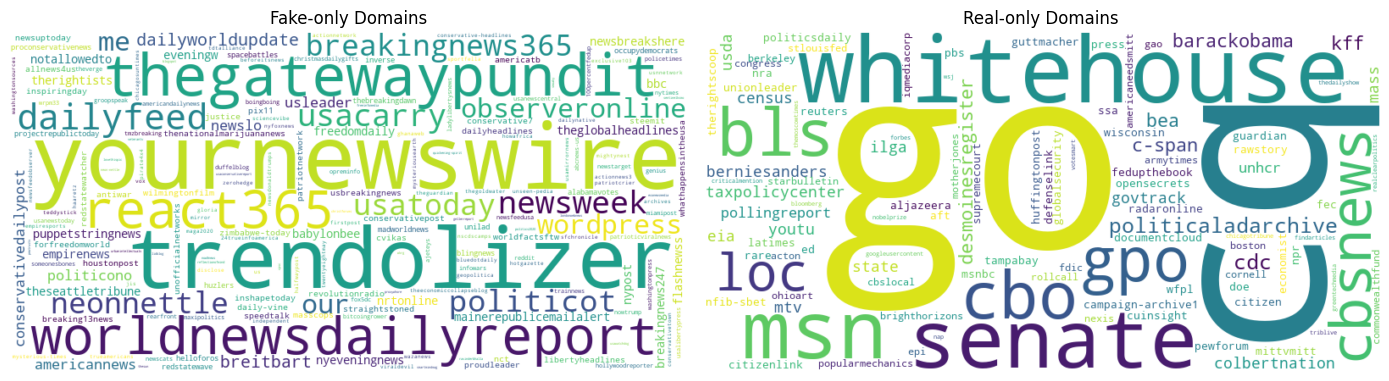

In [184]:
import tldextract
import matplotlib.pyplot as plt

# Extract domains and suffixes for each dataset
for label, df in [("fake", politics_fake_df), ("real", politics_real_df)]:
    df["domain"] = df["news_url"].apply(lambda x: tldextract.extract(str(x)).domain if pd.notnull(x) else "")
    df["suffix"] = df["news_url"].apply(lambda x: tldextract.extract(str(x)).suffix if pd.notnull(x) else "")
    print(f"{label.capitalize()} → {df['domain'].nunique()} unique domains, {df['suffix'].nunique()} unique suffixes")

# Convert to sets for overlap analysis
fake_domains  = set(politics_fake_df["domain"].dropna())
real_domains  = set(politics_real_df["domain"].dropna())
fake_suffixes = set(politics_fake_df["suffix"].dropna())
real_suffixes = set(politics_real_df["suffix"].dropna())

# --- DOMAIN OVERLAP ---
common_domains = fake_domains & real_domains
unique_fake_domains = fake_domains - real_domains
unique_real_domains = real_domains - fake_domains

print("\n DOMAIN COMPARISON")
print(f"Common domains: {len(common_domains)}")
print(f"Unique to fake: {len(unique_fake_domains)}")
print(f"Unique to real: {len(unique_real_domains)}")

print("\nExamples of overlapping domains:", list(common_domains)[:10])
print("Examples unique to fake:", list(unique_fake_domains)[:10])
print("Examples unique to real:", list(unique_real_domains)[:10])

# --- SUFFIX OVERLAP ---
common_suffixes = fake_suffixes & real_suffixes
unique_fake_suffixes = fake_suffixes - real_suffixes
unique_real_suffixes = real_suffixes - fake_suffixes

print("\n SUFFIX COMPARISON")
print(f"Common suffixes: {len(common_suffixes)}")
print(f"Unique to fake: {len(unique_fake_suffixes)}")
print(f"Unique to real: {len(unique_real_suffixes)}")

print("\nCommon suffixes:", common_suffixes)
print("Fake-only suffixes:", unique_fake_suffixes)
print("Real-only suffixes:", unique_real_suffixes)

# --- VISUAL SUMMARY (with corrected label placement) ---
labels = ["Common", "Fake-only", "Real-only"]
domain_counts = [len(common_domains), len(unique_fake_domains), len(unique_real_domains)]
suffix_counts = [len(common_suffixes), len(unique_fake_suffixes), len(unique_real_suffixes)]

domain_colors = ["#66c2a5", "#fc8d62", "#8da0cb"]
suffix_colors = ["#a6d854", "#e78ac3", "#ffd92f"]

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# Domain overlap
axs[0].bar(labels, domain_counts, color=domain_colors, edgecolor='black')
axs[0].set_title("Domain Overlap (Fake vs Real)", pad=15)
axs[0].set_ylabel("Count")
for i, v in enumerate(domain_counts):
    axs[0].text(i, v - (v * 0.05), str(v), ha='center', va='top', fontweight='bold', color='black')

# Suffix overlap
axs[1].bar(labels, suffix_counts, color=suffix_colors, edgecolor='black')
axs[1].set_title("Suffix Overlap (Fake vs Real)", pad=15)
axs[1].set_ylabel("Count")
for i, v in enumerate(suffix_counts):
    axs[1].text(i, v - (v * 0.05), str(v), ha='center', va='top', fontweight='bold', color='black')

plt.tight_layout()
plt.show()

from wordcloud import WordCloud

# --- FILTER DOMAINS: EXCLUDE COMMON + EMPTY ---
fake_domain_series = politics_fake_df.loc[
    (~politics_fake_df["domain"].isin(common_domains)) &
    (politics_fake_df["domain"] != "")
, "domain"]

real_domain_series = politics_real_df.loc[
    (~politics_real_df["domain"].isin(common_domains)) &
    (politics_real_df["domain"] != "")
, "domain"]

# Frequency dicts for word clouds
fake_domain_freq = fake_domain_series.value_counts().to_dict()
real_domain_freq = real_domain_series.value_counts().to_dict()


# --- WORD CLOUDS ---
wc_fake = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(fake_domain_freq)

wc_real = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate_from_frequencies(real_domain_freq)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Fake news domains
axs[0].imshow(wc_fake, interpolation="bilinear")
axs[0].axis("off")
axs[0].set_title("Fake-only Domains")

# Real news domains
axs[1].imshow(wc_real, interpolation="bilinear")
axs[1].axis("off")
axs[1].set_title("Real-only Domains")

plt.tight_layout()
plt.show()



In [185]:
# Calculate percent of real news with real-only domains
real_only_mask = politics_real_df['domain'].isin(unique_real_domains)
percent_real_only_domains = real_only_mask.mean() * 100

# Calculate percent of fake news with fake-only domains
fake_only_mask = politics_fake_df['domain'].isin(unique_fake_domains)
percent_fake_only_domains = fake_only_mask.mean() * 100

print(f"Percent of real news with real-only domains: {percent_real_only_domains:.2f}%")
print(f"Percent of fake news with fake-only domains: {percent_fake_only_domains:.2f}%")

# Calculate percent of real news with real-only domains
real_only_mask = politics_real_df['suffix'].isin(unique_real_suffixes)
percent_real_only_domains = real_only_mask.mean() * 100

# Calculate percent of fake news with fake-only domains
fake_only_mask = politics_fake_df['suffix'].isin(unique_fake_suffixes)
percent_fake_only_domains = fake_only_mask.mean() * 100

print(f"Percent of real news with real-only suffixes: {percent_real_only_domains:.2f}%")
print(f"Percent of fake news with fake-only suffixes: {percent_fake_only_domains:.2f}%")

Percent of real news with real-only domains: 39.26%
Percent of fake news with fake-only domains: 74.77%
Percent of real news with real-only suffixes: 1.28%
Percent of fake news with fake-only suffixes: 13.66%


Analysis of the urls paints a clear picture of the differences between real and fake news. While NLPs can identify text patterns, domains can provide a quick heuristic to identify fake news. 

For clarity, the domain is the main part of the URL, i.e. "cnn" in "www.cnn.com". The suffix is the ending of the URL, i.e. "com" in "www.cnn.com". If the "cnn" domain is present in the fake news dataset, it is a common domain. If it is only present in the fake news dataset, it is a fake-only domain and if it is only present in the real news dataset, it is a real-only domain. The same logic applies to suffixes.

There are common suffix between real and fake news, but there are also many unique suffixes. As expected, the fake news dataset contains foreign government such as "rt" (Russia), "is" (Iceland), and "gov.jm" (Jamaica). 

If we search for domains and suffixes that are unique to either dataset, the only useful pattern is fake-only domains. 75% of all fake news comes from domains that are unique to fake news. We cannot reliably predict based on real-only domains as 60% of real news uses common domains. 

Article titles provide minimal text compared to the article itself, but this data can be crucial in idenfting fake news. For example, it's highly unlikely that a shocking title would have mundane text and vice versa. Shocking titles accompany shocking text. We expect fake news articles to be more engaging, shocking, and inflamatory. The question is whether or not an NLP will pick up on these patterns.

--- Real ---
       textblob_polarity  vader_compound
count         624.000000      624.000000
mean            0.038518        0.015800
std             0.161547        0.282908
min            -0.700000       -0.959000
25%             0.000000        0.000000
50%             0.000000        0.000000
75%             0.000000        0.000000
max             1.000000        0.844200 

--- Fake ---
       textblob_polarity  vader_compound
count         432.000000      432.000000
mean            0.005980       -0.162425
std             0.222265        0.398981
min            -1.000000       -0.942300
25%             0.000000       -0.510600
50%             0.000000        0.000000
75%             0.000000        0.000000
max             0.900000        0.942300 



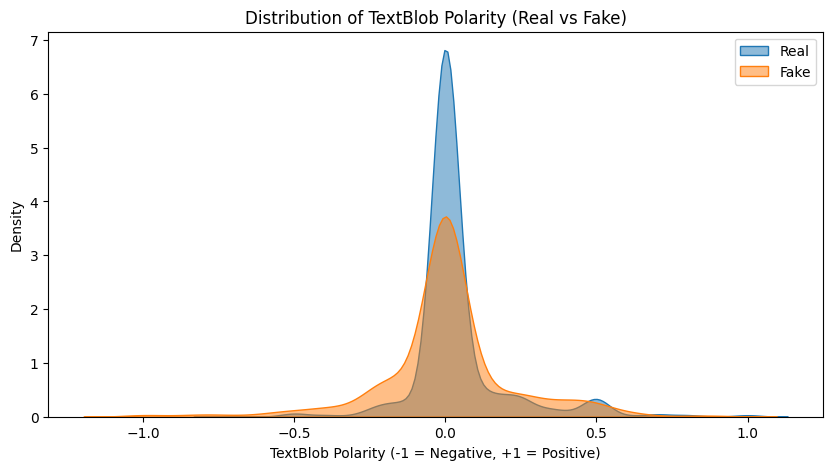

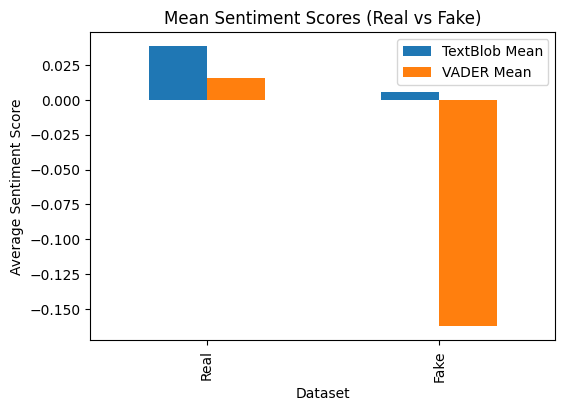

Real correlation: 0.225
Fake correlation: 0.323
TextBlob polarity difference: TtestResult(statistic=2.754256687940033, pvalue=0.005983787382996053, df=1054.0)
VADER compound difference: TtestResult(statistic=8.493426981968938, pvalue=6.752670826488444e-17, df=1054.0)


In [186]:
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

for df in [politics_real_df, politics_fake_df]:
    df["textblob_polarity"] = df["title"].apply(lambda x: TextBlob(str(x)).sentiment.polarity)
    df["vader_compound"] = df["title"].apply(lambda x: analyzer.polarity_scores(str(x))['compound'])


for label, df in [("Real", politics_real_df), ("Fake", politics_fake_df)]:
    print(f"--- {label} ---")
    print(df[["textblob_polarity", "vader_compound"]].describe(), "\n")

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.kdeplot(politics_real_df['textblob_polarity'], label='Real', fill=True, alpha=0.5)
sns.kdeplot(politics_fake_df['textblob_polarity'], label='Fake', fill=True, alpha=0.5)
plt.title("Distribution of TextBlob Polarity (Real vs Fake)")
plt.xlabel("TextBlob Polarity (-1 = Negative, +1 = Positive)")
plt.legend()
plt.show()


means = {
    'Dataset': ['Real', 'Fake'],
    'TextBlob Mean': [
        politics_real_df['textblob_polarity'].mean(),
        politics_fake_df['textblob_polarity'].mean()
    ],
    'VADER Mean': [
        politics_real_df['vader_compound'].mean(),
        politics_fake_df['vader_compound'].mean()
    ]
}

mean_df = pd.DataFrame(means).set_index('Dataset')
mean_df.plot(kind='bar', figsize=(6,4), title='Mean Sentiment Scores (Real vs Fake)')
plt.ylabel('Average Sentiment Score')
plt.show()


for label, df in [("Real", politics_real_df), ("Fake", politics_fake_df)]:
    corr = df['textblob_polarity'].corr(df['vader_compound'])
    print(f"{label} correlation: {corr:.3f}")


from scipy.stats import ttest_ind

t1 = ttest_ind(politics_real_df['textblob_polarity'], politics_fake_df['textblob_polarity'], nan_policy='omit')
t2 = ttest_ind(politics_real_df['vader_compound'], politics_fake_df['vader_compound'], nan_policy='omit')

print("TextBlob polarity difference:", t1)
print("VADER compound difference:", t2)


In [187]:
politics_real_df.to_csv('politics_real_df.csv', index=False)
politics_fake_df.to_csv('politics_fake_df.csv', index=False)

In [191]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from xgboost import XGBClassifier
import numpy as np
import pandas as pd

# Combine real and fake dataframes
politics_real_df['real'] = 1
politics_fake_df['real'] = 0
combined_df = pd.concat([politics_real_df, politics_fake_df], ignore_index=True)

# Prepare features and target
X = combined_df[['domain', 'suffix', 'textblob_polarity', 'vader_compound']]
y = combined_df['real']

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Define which columns are categorical vs numeric
cat_features = ['domain', 'suffix']
num_features = ['textblob_polarity', 'vader_compound']

# Preprocess: one-hot encode categoricals, pass through numerics
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("num", "passthrough", num_features)
    ]
)

# XGBoost classifier
xgb_clf = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    random_state=42,
    eval_metric="logloss"
)

# Full pipeline
model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("xgb", xgb_clf)
])

# Fit
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake (0)", "Real (1)"],
    digits=3
))

# ===== Feature Importances =====
# Get the trained preprocessor and model
preprocessor = model.named_steps["preprocess"]
xgb_model = model.named_steps["xgb"]

# Get feature names for the one-hot encoded categoricals
ohe = preprocessor.named_transformers_["cat"]
cat_feature_names = ohe.get_feature_names_out(cat_features)

# Full list of feature names in the order seen by XGBoost
all_feature_names = np.concatenate([cat_feature_names, num_features])

# Get importances from XGBoost
importances = xgb_model.feature_importances_

# Put into a DataFrame for readability
feat_imp_df = pd.DataFrame({
    "feature": all_feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

print("\nTop 20 features by importance:")
print(feat_imp_df.head(20).to_string(index=False))


              precision    recall  f1-score   support

    Fake (0)      0.745     0.805     0.773        87
    Real (1)      0.856     0.808     0.831       125

    accuracy                          0.807       212
   macro avg      0.800     0.806     0.802       212
weighted avg      0.810     0.807     0.808       212


Top 20 features by importance:
              feature  importance
           suffix_gov    0.073142
       domain_youtube    0.063100
  domain_yournewswire    0.061868
              domain_    0.055290
          suffix_news    0.054852
    domain_politifact    0.052138
           suffix_net    0.047320
       domain_nytimes    0.045229
            domain_go    0.042527
           suffix_org    0.041577
           domain_msn    0.041126
              suffix_    0.038259
       vader_compound    0.036830
       domain_foxnews    0.036311
   domain_trendolizer    0.034909
            domain_cq    0.033964
           domain_cnn    0.032022
domain_washingtonpost    0.02